# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 12: Diversity Analysis

### Objective

If all generated images of a person were identical, they would be useless for training. If they were all different but not recognisably that person, they would be harmful. This notebook measures **how varied the synthetic images are while the identity stays the same**:

```text
one identity  ->  many synthetic images  ->  how different are they from each other (variation)
                                             how different are they from other people (identity)
                                             how different are they from the real images (novelty)
```

The notebook must:

1. Compute the distribution metrics **FID** and **KID** (generated images against real images).
2. Compute the pairwise metrics **LPIPS**, **MS-SSIM**, and a plain pixel difference within and between identities.
3. Do this for **all** generated images and for the images **accepted** by Notebook 11, to see whether the filter removed variation.
4. Visualise **identity to variation**: real images next to generated variations, distance distributions, and a 2-D projection of the features.
5. Save `diversity_report.csv`.

### Important boundary of this notebook

This notebook performs **measurement only**.

It does not generate, filter, or modify any image, and it does not train a model. It only reads the real few-shot images (Notebook 06), the synthetic images (Notebook 10), and the accepted list (Notebook 11).

## 1. Research rationale

### 1.1 Two kinds of measurement

| Kind | Metrics | Question |
|---|---|---|
| **Distribution** (a whole set against a whole set) | **FID**, **KID** | Does the set of generated images look like the set of real images, and does it cover the same range? |
| **Pairwise** (image against image) | **LPIPS**, **MS-SSIM**, pixel L1 | How different are two images? Measured within one identity, between identities, and against the real images |

### 1.2 FID and KID

Both compare the **features** of two image sets.

- **FID** fits a Gaussian to each set and measures the Frechet distance between them. It is biased when a set is small (the covariance is poorly estimated), so FID values only compare fairly at similar sample sizes.
- **KID** is an *unbiased* kernel distance (a polynomial-kernel MMD) averaged over random subsets. It is the better choice for small sets, which is why both are reported.
- **Feature spaces.** `inception`: torchvision's ImageNet Inception-v3, strips enlarged x2 and the gray channel repeated three times. `recognizer`: the embedding of the Notebook 07 recognizer, which was trained on iris textures. The Inception values are **not comparable with published FID numbers** (different weights, grayscale strips); they are only for comparing generated sets with each other and with the reference below.
- **A floor for context.** FID/KID between two *real* sets of different people (validation identities against the training images) shows what "real versus different real" looks like at this sample size. A generated set that is close to that floor is about as realistic as a new real set can be.

### 1.3 Pairwise metrics

| Metric | Meaning | Note |
|---|---|---|
| **LPIPS** | Perceptual distance (deep features); larger = more different | Needs the `lpips` package (`pip install lpips`). Otherwise an **unweighted AlexNet-feature proxy** is used, and the report says so |
| **1 - MS-SSIM** | Structural dissimilarity; larger = more different | Only **3 scales** (the strips are 64 pixels high; the usual 5 scales need at least about 160) |
| **Pixel L1** | Mean absolute pixel difference | A crude baseline: it reacts to rotation and brightness |

### 1.4 Identity to variation

For each metric, five average distances are computed, from random pairs of images:

| Quantity | Pairs |
|---|---|
| `within` | two generated images of the **same** identity (the variation) |
| `real_within` | two real images of the same identity (the natural variation) |
| `between` | generated images of **different** identities |
| `real_between` | real images of different identities |
| `to_real` | a generated image and a real image of the **same** identity (novelty) |

Three ratios read the result:

| Ratio | Definition | Good looks like |
|---|---|---|
| **Diversity ratio** | `within / real_within` | Around 1: as varied as real images. Much below 1: mode collapse. Far above 1: noise or artefacts |
| **Separation** | `between / within` | Clearly above 1 (and similar to the real value `real_between / real_within`): images of one person are closer to each other than to other people |
| **Novelty ratio** | `to_real / real_within` | Not near 0 (near 0 = copies of the real images) |

### 1.5 What these numbers cannot tell

- They do **not** say that an image shows the right person: that is Notebook 11's identity check.
- High diversity can also come from noise. Always read the figures and the FID/KID together with the diversity ratio.
- The pairwise numbers use a random sample of identities (`DIVERSITY_IDENTITIES`) and pairs (`PAIRS_PER_IDENTITY`); the report states how many.

### 1.6 Reference images and leakage rules

- **Real reference for FID/KID:** the real `train / support` images (what the generator saw). **Floor:** real images of the validation people.
- **Real within-identity reference:** the real `train / support` images **plus the held-out `train / query` images of the same people** (`USE_TRAIN_QUERY_AS_REFERENCE`). They are used **only** as a reference for natural variation in this measurement; with 1-shot there is otherwise a single real image per person and no real pairs exist. No model is trained here.
- Only synthetic images of **training identities** are analysed; the notebook asserts that every identity is a `train / support` identity and that no person is shared with another split.

### 1.7 Things to keep in mind

- **Run `QUICK_TEST = True` first.**
- **Time:** feature extraction for FID/KID is the slow part (a few thousand images per set and shot); `MAX_FID_IMAGES` limits it.
- **Windows:** no NumPy matrix multiplication is used (PyTorch does all linear algebra); PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import itertools
import json
import math
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 12 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

# ImageNet weights downloaded by torchvision (Inception, AlexNet) are kept inside the project.
(PROJECT_ROOT / "pretrained_models").mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(PROJECT_ROOT / "pretrained_models" / "torch_hub"))

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches.

- `QUICK_TEST = True` analyses the few images of Notebook 10's quick test with tiny sample sizes. It reads the **quick-test outputs of Notebooks 07, 10 and 11** and writes to a separate folder.
- `ANALYSE_ACCEPTED = True` also analyses the images accepted by Notebook 11 (it needs that notebook's output). Set it to `False` to analyse all generated images only.
- `FEATURE_SPACES` chooses where FID and KID are computed. A space whose model cannot be loaded is skipped with a warning.
- `MAX_FID_IMAGES` caps the number of images per set for FID/KID; `KID_SUBSETS` and `KID_SUBSET_SIZE` control the KID estimate.
- `DIVERSITY_IDENTITIES` and `PAIRS_PER_IDENTITY` control the pairwise sample; `DIVERSITY_SEED` makes it reproducible.
- `LPIPS_MODE = "auto"` uses the `lpips` package if installed, otherwise an unweighted AlexNet proxy; `"off"` skips LPIPS.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = analyse the quick-test images of Notebook 10

# ---- what to analyse ----
SHOTS_TO_RUN = [1, 2, 3, 5]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]
GENERATOR_SEED = 42                     # the Notebook 09 / 10 run: diffusion__<K>shot__seed<GENERATOR_SEED>
UPSTREAM_FROM_QUICKTEST = QUICK_TEST    # QUICK_TEST reads the quick-test outputs of Notebooks 07, 10, 11
ANALYSE_ACCEPTED = True                 # also analyse the images accepted by Notebook 11

INPUT_HW = (64, 512)

# ---- distribution metrics (FID, KID) ----
FEATURE_SPACES = ["inception", "recognizer"]
RECOGNIZER_BACKBONE = "efficientnet_b0"         # Notebook 07 checkpoint:
RECOGNIZER_VARIANT = "real_traditional_aug"     #   <variant>__<backbone>__<K>shot__seed<RECOGNIZER_SEED>.pt
RECOGNIZER_SEED = 42
INCEPTION_SCALE = 2             # strips are enlarged by this factor before Inception (at least 2)
MAX_FID_IMAGES = 5000           # images per set
KID_SUBSETS = 50
KID_SUBSET_SIZE = 1000
FEATURE_BATCH_SIZE = 64

# ---- pairwise metrics (LPIPS, MS-SSIM, L1) ----
LPIPS_MODE = "auto"             # "auto" or "off"
MSSSIM_WEIGHTS = (0.0448, 0.2856, 0.3001)    # first three standard weights (renormalised): 3 scales for 64-pixel-high strips
DIVERSITY_IDENTITIES = 200
PAIRS_PER_IDENTITY = 20
USE_TRAIN_QUERY_AS_REFERENCE = True     # real within-identity reference also uses held-out train/query images
PAIR_BATCH_SIZE = 64
DIVERSITY_SEED = 777

# ---- figures ----
FIGURE_IDENTITIES = 3
FIGURE_GENERATED = 5
PCA_IDENTITIES = 8

# ---- bookkeeping ----
RESUME = True

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    RECOGNIZER_BACKBONE = "resnet50"        # the only backbone Notebook 07's quick test trains
    RECOGNIZER_VARIANT = "real_only"        # the only variant Notebook 07's quick test trains
    MAX_FID_IMAGES = 200
    KID_SUBSETS = 5
    KID_SUBSET_SIZE = 50
    DIVERSITY_IDENTITIES = 6
    PAIRS_PER_IDENTITY = 6
    PCA_IDENTITIES = 4
    THRESHOLD_MODE, FIXED_THRESHOLD = "fixed", -1.0     # quick test only: accept every non-degenerate image
    print("QUICK_TEST is ON: tiny sample sizes, separate output folders, reads the quick-test outputs of Notebooks 07, 10, 11.")

# ---- sanity checks on the configuration itself ----
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert len(FEATURE_SPACES) >= 1 and set(FEATURE_SPACES) <= {"inception", "recognizer"}, "FEATURE_SPACES must be a subset of ['inception', 'recognizer']"
assert INCEPTION_SCALE >= 2, "Inception needs inputs of at least 75 pixels: INCEPTION_SCALE must be at least 2"
assert LPIPS_MODE in {"auto", "off"}, "LPIPS_MODE must be 'auto' or 'off'"
assert RECOGNIZER_VARIANT in {"real_only", "real_traditional_aug"}, "Unknown RECOGNIZER_VARIANT"
assert len(MSSSIM_WEIGHTS) == 3 and all(w > 0 for w in MSSSIM_WEIGHTS), "MS-SSIM uses exactly 3 scales here"
assert DIVERSITY_IDENTITIES >= 2 and PAIRS_PER_IDENTITY >= 1 and KID_SUBSETS >= 1 and KID_SUBSET_SIZE >= 2
assert len(SHOTS_TO_RUN) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Shots:", SHOTS_TO_RUN, "| feature spaces:", FEATURE_SPACES, "| analyse accepted images:", ANALYSE_ACCEPTED, "| device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: no CUDA GPU found. Feature extraction for FID/KID is slow on CPU; use QUICK_TEST = True.")

Shots: [1, 2, 3, 5] | feature spaces: ['inception', 'recognizer'] | analyse accepted images: True | device: cuda


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
SYNTHETIC_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
SYNTHETIC_MANIFEST_PATH = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
ACCEPTED_MANIFEST_PATH = PROJECT_ROOT / "results" / f"identity_verification{upstream_suffix}" / "accepted_manifest.csv"
RECOGNIZER_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{upstream_suffix}"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"synthetic_diversity{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
DISTANCES_DIR = RESULTS_DIR / "distances"

for directory in [RESULTS_DIR, RUNS_DIR, DISTANCES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Synthetic images (read):", SYNTHETIC_DIR)
print("Notebook 12 results:", RESULTS_DIR)

Synthetic images (read): E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images
Notebook 12 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity


## 5. Utility functions

Real images are read once and cached. Synthetic images are never resized: a wrong-size file stops the notebook, because Notebook 10 guarantees the size. `verify_id` is built exactly as in Notebook 11, so the generated and accepted lists can be matched.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def file_signature(path):
    '''Size and modification time: changes whenever the file is rewritten.'''
    stat = Path(path).stat()
    return [int(stat.st_size), int(stat.st_mtime)]


def make_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


def recognizer_path(shot):
    return RECOGNIZER_DIR / f"{RECOGNIZER_VARIANT}__{RECOGNIZER_BACKBONE}__{shot}shot__seed{RECOGNIZER_SEED}.pt"


def add_verify_id(table):
    table["verify_id"] = (table["generator_run_id"] + "|" + table["class_id"]
                          + "|syn_" + table["synth_index"].astype(int).map("{:03d}".format))
    return table


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def read_synthetic(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None or image.shape != tuple(INPUT_HW):
        raise ValueError(f"Synthetic image is missing, unreadable, or not {INPUT_HW}: {path}")
    return image


def stack_synthetic(relative_paths):
    return torch.from_numpy(np.stack([read_synthetic(SYNTHETIC_DIR / p) for p in relative_paths]))


def safe_mean(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    return float(values.mean()) if len(values) else float("nan")


def ratio(numerator, denominator):
    if not np.isfinite(numerator) or not np.isfinite(denominator) or denominator == 0:
        return float("nan")
    return float(numerator / denominator)

## 6. Load the datasets and check the upstream outputs

- `fewshot_manifest_long.csv` (Notebook 06): the **real** images.
- `synthetic_manifest.csv` (Notebook 10): every generated image.
- `accepted_manifest.csv` (Notebook 11): the generated images that passed identity verification (only if `ANALYSE_ACCEPTED`).

Before anything starts, the notebook checks that the images exist, that the accepted images are a subset of the generated ones, and that all synthetic images are marked as training images of training identities.

In [6]:
# ============================================================
# 6. Load the datasets
# ============================================================

for path, hint in [(MANIFEST_LONG_PATH, "06_FewShot_Dataset_Creation.ipynb"),
                   (SYNTHETIC_MANIFEST_PATH, "10_Synthetic_Image_Generation.ipynb (run it to the end)")]:
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}\nRun {hint} first.")

if ANALYSE_ACCEPTED and not ACCEPTED_MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Missing: {ACCEPTED_MANIFEST_PATH}\nRun 11_Identity_Verification.ipynb first, "
        "or set ANALYSE_ACCEPTED = False to analyse all generated images only.")

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})
synthetic_manifest = add_verify_id(pd.read_csv(SYNTHETIC_MANIFEST_PATH, dtype={"identity": str, "eye": str}))
accepted_manifest = (add_verify_id(pd.read_csv(ACCEPTED_MANIFEST_PATH, dtype={"identity": str, "eye": str}))
                     if ANALYSE_ACCEPTED else None)

required_real = {"shot", "image_id", "dataset", "class_id", "subject_key", "split", "role", "relative_path", "source_path"}
required_synthetic = {"class_id", "dataset", "subject_key", "shot", "split", "synth_index", "relative_path", "generator_run_id"}

for name, table, required in [("Notebook 06", long_manifest, required_real), ("Notebook 10", synthetic_manifest, required_synthetic)]:
    missing = required.difference(table.columns)
    if missing:
        raise ValueError(f"{name} manifest is missing required columns: {sorted(missing)}")

assert synthetic_manifest["verify_id"].is_unique, "verify_id is not unique in the Notebook 10 manifest"

if accepted_manifest is not None:
    assert accepted_manifest["verify_id"].is_unique, "verify_id is not unique in the accepted manifest"
    assert set(accepted_manifest["verify_id"]) <= set(synthetic_manifest["verify_id"]), \
        "the accepted manifest contains images that are not in the Notebook 10 manifest (different run?)"

available_datasets = sorted(long_manifest["dataset"].unique())
for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, f"TRAIN_DATASETS contains '{dataset_name}', not in {available_datasets}"

shots_available = sorted(synthetic_manifest["shot"].unique())
shots_to_run = [k for k in SHOTS_TO_RUN if k in shots_available]
for k in SHOTS_TO_RUN:
    if k not in shots_available:
        print(f"WARNING: {k}-shot has no synthetic images in the Notebook 10 manifest; skipping it.")
if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the Notebook 10 manifest.")

# feature spaces: the recognizer space needs a Notebook 07 checkpoint for every shot
feature_spaces = list(FEATURE_SPACES)
if "recognizer" in feature_spaces:
    missing_recognizers = [str(recognizer_path(s)) for s in shots_to_run if not recognizer_path(s).exists()]
    if missing_recognizers:
        print("WARNING: Notebook 07 recognizer checkpoints are missing, so the 'recognizer' feature space is skipped:")
        for p in missing_recognizers[:4]:
            print("   ", p)
        feature_spaces.remove("recognizer")
if not feature_spaces:
    raise RuntimeError("No feature space is available for FID/KID.")

# leakage guards and file checks
for shot in shots_to_run:
    run_id = make_run_id(shot)
    rows = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == run_id)]
    assert len(rows) > 0, f"no rows for {run_id} in the Notebook 10 manifest"

    real = long_manifest[long_manifest["shot"] == shot]
    train_support = real[(real["split"] == "train") & (real["role"] == "support") & (real["dataset"].isin(TRAIN_DATASETS))]
    assert (rows["split"] == "train").all(), f"{shot}-shot: a synthetic image is not labelled as a training image"
    assert set(rows["class_id"]) <= set(train_support["class_id"]), f"{shot}-shot: a synthetic identity is not a training identity"
    held_out = set(real.loc[~real["class_id"].isin(set(train_support["class_id"])), "subject_key"])
    assert not (set(rows["subject_key"]) & held_out), f"{shot}-shot: a synthetic identity shares a person with another split"

    absent = [p for p in rows["relative_path"].head(2000) if not (SYNTHETIC_DIR / p).exists()]
    assert not absent, f"{shot}-shot: {len(absent)} synthetic images are missing from {SYNTHETIC_DIR} (checked a sample)"

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)
print("Feature spaces:", feature_spaces)

summary_rows = [{"shot": shot,
                 "generated_images": int(((synthetic_manifest["shot"] == shot)).sum()),
                 "accepted_images": int((accepted_manifest["shot"] == shot).sum()) if accepted_manifest is not None else None,
                 "identities": int(synthetic_manifest.loc[synthetic_manifest["shot"] == shot, "class_id"].nunique())}
                for shot in shots_to_run]
display(pd.DataFrame(summary_rows))

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "generator_seed": GENERATOR_SEED, "analyse_accepted": ANALYSE_ACCEPTED,
    "feature_spaces": feature_spaces,
    "recognizer": [RECOGNIZER_BACKBONE, RECOGNIZER_VARIANT, RECOGNIZER_SEED],
    "fid_kid": [INCEPTION_SCALE, MAX_FID_IMAGES, KID_SUBSETS, KID_SUBSET_SIZE],
    "pairs": [LPIPS_MODE, list(MSSSIM_WEIGHTS), DIVERSITY_IDENTITIES, PAIRS_PER_IDENTITY, USE_TRAIN_QUERY_AS_REFERENCE, DIVERSITY_SEED],
    "upstream_from_quicktest": UPSTREAM_FROM_QUICKTEST,
    "recognizer_signatures": {str(s): file_signature(recognizer_path(s)) for s in shots_to_run if "recognizer" in feature_spaces},
    "synthetic_manifest_digest": file_digest(SYNTHETIC_MANIFEST_PATH),
    "accepted_manifest_digest": file_digest(ACCEPTED_MANIFEST_PATH) if ANALYSE_ACCEPTED else None,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]
Feature spaces: ['inception', 'recognizer']


,shot,generated_images,accepted_images,identities
0,1,26410,336,1390
1,2,24912,320,1384
2,3,23273,338,1369
3,5,19410,267,1294


Configuration fingerprint: fb203fed35db


## 7. Feature extractors for FID and KID

- **`recognizer`**: `RecognizerNet` is **copied from Notebook 07** (backbone + 256-d embedding layer); the checkpoint is loaded without downloading anything. Its 256-d embedding is the feature.
- **`inception`**: torchvision's Inception-v3 with ImageNet weights (downloaded once into `pretrained_models/torch_hub`). The strip is enlarged by `INCEPTION_SCALE`, the gray channel repeated three times, and the 2048-d pooled feature is used. If the weights cannot be downloaded, this space is skipped with a warning.

Both models are used in evaluation mode and are never updated.

In [7]:
# ============================================================
# 7. Feature extractors
# ============================================================

KNOWN_BACKBONES = {"resnet50": 2048, "efficientnet_b0": 1280, "efficientnet_b3": 1536, "vit_b_16": 768}
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


class RecognizerNet(nn.Module):
    '''Same structure as Notebook 07's EmbeddingNet (without pretrained-weight loading).'''

    def __init__(self, backbone_name, embedding_dim, vit_input_size):
        super().__init__()
        backbone = getattr(tv_models, backbone_name)(weights=None)

        if backbone_name.startswith("resnet"):
            backbone.fc = nn.Identity()
        elif backbone_name.startswith("efficientnet"):
            backbone.classifier = nn.Identity()
        elif backbone_name.startswith("vit"):
            backbone.heads = nn.Identity()
        else:
            raise ValueError(backbone_name)

        self.backbone = backbone
        self.is_vit = backbone_name.startswith("vit")
        self.vit_input_size = vit_input_size
        self.embed = nn.Sequential(nn.Linear(KNOWN_BACKBONES[backbone_name], embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.is_vit:
            x = F.interpolate(x, size=(self.vit_input_size, self.vit_input_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def load_recognizer(path, shot):
    checkpoint = torch_load(path)
    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), "the recognizer was trained on a different image size"
    assert int(checkpoint["shot"]) == int(shot), f"the recognizer checkpoint is for {checkpoint['shot']}-shot, not {shot}-shot"

    model = RecognizerNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval()


class FeatureExtractor:
    '''function: float image batch [B, 1, 64, 512] in [0, 1] -> features [B, D].'''

    def __init__(self, name, function):
        self.name = name
        self.function = function


@torch.no_grad()
def extract_features(extractor, images_uint8):
    '''Features (float64, CPU) of a uint8 image tensor [N, H, W].'''
    parts = []
    for start in range(0, len(images_uint8), FEATURE_BATCH_SIZE):
        x = images_uint8[start:start + FEATURE_BATCH_SIZE].to(DEVICE).float().div_(255.0).unsqueeze(1)
        parts.append(extractor.function(x).double().cpu())
    return torch.cat(parts)


def load_inception_extractor():
    '''Inception-v3 with ImageNet weights; returns None (with a warning) if the weights cannot be loaded.'''
    try:
        model = tv_models.inception_v3(weights="DEFAULT")
    except Exception as error:
        print(f"WARNING: could not load the Inception-v3 weights ({type(error).__name__}: {str(error)[:100]}). "
              "The 'inception' feature space is skipped.")
        return None

    model.fc = nn.Identity()
    model = model.to(DEVICE).eval()

    def function(x):
        x = F.interpolate(x.expand(-1, 3, -1, -1), scale_factor=INCEPTION_SCALE, mode="bilinear", align_corners=False)
        return model((x - IMAGENET_MEAN) / IMAGENET_STD)

    return FeatureExtractor("inception", function)


EXTRACTOR_CACHE = {}


def get_extractors(shot):
    '''The feature extractors that are available for this shot.'''
    extractors = {}

    if "inception" in feature_spaces:
        if "inception" not in EXTRACTOR_CACHE:
            EXTRACTOR_CACHE["inception"] = load_inception_extractor()
        if EXTRACTOR_CACHE["inception"] is not None:
            extractors["inception"] = EXTRACTOR_CACHE["inception"]

    if "recognizer" in feature_spaces:
        model = load_recognizer(recognizer_path(shot), shot)
        extractors["recognizer"] = FeatureExtractor("recognizer", lambda x, m=model: m(x))

    return extractors


# the copied recognizer must build and run (random weights, nothing is downloaded)
probe_net = RecognizerNet(RECOGNIZER_BACKBONE, 256, 224).to(DEVICE).eval()
with torch.no_grad():
    probe_features = probe_net(torch.rand(2, 1, *INPUT_HW, device=DEVICE))
assert probe_features.shape == (2, 256) and torch.isfinite(probe_features).all(), "RecognizerNet is broken"
del probe_net

print("Feature extractors defined.")

Feature extractors defined.


## 8. Pairwise distances: pixel L1, MS-SSIM, LPIPS

- **MS-SSIM** is implemented here in PyTorch: SSIM computed with a 7x7 Gaussian window, on **3 scales** (the image is halved twice). The contrast-structure term is used at the first two scales and the full SSIM at the last; the three terms are combined with the weights in `MSSSIM_WEIGHTS`. The notebook reports the **dissimilarity** `1 - MS-SSIM` (larger = more different).
- **LPIPS** uses the `lpips` package if it is installed (`pip install lpips`, AlexNet with learned weights). Otherwise it falls back to an **unweighted** AlexNet-feature distance (the same idea without the learned weights); the report states which version was used. `LPIPS_MODE = "off"` skips it.
- **Pixel L1** is the mean absolute pixel difference.

The next cell tests MS-SSIM and the pair functions on cases with known answers.

In [8]:
# ============================================================
# 8. Pairwise distances
# ============================================================

def gaussian_window(size=7, sigma=1.5):
    coordinates = torch.arange(size, dtype=torch.float32) - (size - 1) / 2.0
    window = torch.exp(-(coordinates ** 2) / (2 * sigma ** 2))
    return window / window.sum()


def _gaussian_filter(x, window):
    '''Separable Gaussian filter with valid padding. x: [B, 1, H, W].'''
    vertical = window.view(1, 1, -1, 1).to(x)
    horizontal = window.view(1, 1, 1, -1).to(x)
    return F.conv2d(F.conv2d(x, vertical), horizontal)


def ms_ssim(x, y, weights=MSSSIM_WEIGHTS, window_size=7, sigma=1.5):
    '''Multi-scale SSIM of two batches [B, 1, H, W] with values in [0, 1]. Returns [B].'''
    window = gaussian_window(window_size, sigma)
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    weights = torch.tensor(weights, dtype=torch.float32, device=x.device)
    weights = weights / weights.sum()
    values = []

    for level in range(len(weights)):
        mu_x, mu_y = _gaussian_filter(x, window), _gaussian_filter(y, window)
        var_x = _gaussian_filter(x * x, window) - mu_x ** 2
        var_y = _gaussian_filter(y * y, window) - mu_y ** 2
        covariance = _gaussian_filter(x * y, window) - mu_x * mu_y

        contrast_structure = (2 * covariance + c2) / (var_x + var_y + c2)

        if level == len(weights) - 1:
            luminance = (2 * mu_x * mu_y + c1) / (mu_x ** 2 + mu_y ** 2 + c1)
            values.append((luminance * contrast_structure).mean(dim=(1, 2, 3)))
        else:
            values.append(contrast_structure.mean(dim=(1, 2, 3)))
            x, y = F.avg_pool2d(x, 2), F.avg_pool2d(y, 2)

    stacked = torch.stack(values, dim=1).clamp(min=1e-6)
    return torch.prod(stacked ** weights, dim=1)


class PerceptualDistance:
    '''LPIPS (package) or an unweighted AlexNet-feature proxy; model is None when LPIPS is off or unavailable.'''

    def __init__(self, mode):
        self.model = None
        self.kind = "off"
        self.implementation = "off"

        if mode == "off":
            return

        try:
            import lpips
            self.model = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
            self.kind, self.implementation = "lpips", "lpips package (AlexNet, learned weights)"
            return
        except Exception as error:
            print(f"NOTE: the 'lpips' package is not available ({type(error).__name__}). "
                  "Install it with `pip install lpips` for the standard LPIPS. Trying the proxy instead.")

        try:
            self.model = tv_models.alexnet(weights="DEFAULT").features.to(DEVICE).eval()
            self.kind, self.implementation = "proxy", "unweighted AlexNet features (LPIPS proxy, no learned weights)"
        except Exception as error:
            print(f"WARNING: the AlexNet weights could not be loaded ({type(error).__name__}); LPIPS is skipped.")
            self.model = None

    @torch.no_grad()
    def __call__(self, a, b):
        '''a, b: float [B, 1, H, W] in [0, 1] on DEVICE. Returns [B] on the CPU (NaN if unavailable).'''
        if self.model is None:
            return torch.full((len(a),), float("nan"))

        a, b = a.expand(-1, 3, -1, -1), b.expand(-1, 3, -1, -1)

        if self.kind == "lpips":
            return self.model(a * 2 - 1, b * 2 - 1).flatten().cpu()

        a, b = (a - IMAGENET_MEAN) / IMAGENET_STD, (b - IMAGENET_MEAN) / IMAGENET_STD
        total = 0.0
        for index, layer in enumerate(self.model):
            a, b = layer(a), layer(b)
            if index in (1, 4, 7, 9, 11):                    # the five ReLU outputs LPIPS uses
                total = total + (F.normalize(a, dim=1) - F.normalize(b, dim=1)).pow(2).mean(dim=(1, 2, 3))
        return total.cpu()


PERCEPTUAL = PerceptualDistance(LPIPS_MODE)
METRICS = ["l1", "msssim", "lpips"]          # msssim is stored as the dissimilarity 1 - MS-SSIM
print("LPIPS implementation:", PERCEPTUAL.implementation)


@torch.no_grad()
def pair_metrics(pairs, store):
    '''pairs: [((name, class, i), (name, class, j)), ...] referring to images in store[(name, class)] (uint8 [n, H, W]).'''
    if not pairs:
        return {metric: np.array([], dtype=np.float64) for metric in METRICS}

    results = {metric: [] for metric in METRICS}

    for start in range(0, len(pairs), PAIR_BATCH_SIZE):
        chunk = pairs[start:start + PAIR_BATCH_SIZE]
        a = torch.stack([store[(n, c)][i] for (n, c, i), _ in chunk]).to(DEVICE).float().div_(255.0).unsqueeze(1)
        b = torch.stack([store[(n, c)][j] for _, (n, c, j) in chunk]).to(DEVICE).float().div_(255.0).unsqueeze(1)

        results["l1"].append((a - b).abs().mean(dim=(1, 2, 3)).cpu())
        results["msssim"].append((1.0 - ms_ssim(a, b)).cpu())
        results["lpips"].append(PERCEPTUAL(a, b))

    return {metric: torch.cat(parts).numpy().astype(np.float64) for metric, parts in results.items()}


# ---- self-tests on cases with known answers ----
torch.manual_seed(0)
x_test = torch.rand(4, 1, *INPUT_HW, device=DEVICE)
y_test = torch.rand(4, 1, *INPUT_HW, device=DEVICE)
noisy_test = (x_test + 0.1 * torch.randn_like(x_test)).clamp(0, 1)

assert torch.allclose(ms_ssim(x_test, x_test), torch.ones(4, device=DEVICE), atol=1e-4), "MS-SSIM of an image with itself must be 1"
assert torch.allclose(ms_ssim(x_test, y_test), ms_ssim(y_test, x_test), atol=1e-5), "MS-SSIM must be symmetric"
assert bool((ms_ssim(x_test, noisy_test) < 0.999).all()), "adding noise must lower MS-SSIM"
assert bool((ms_ssim(x_test, noisy_test) > ms_ssim(x_test, y_test)).all()), "a lightly noisy copy must be more similar than an unrelated image"
assert bool((ms_ssim(x_test, y_test) < 0.5).all()), "unrelated noise images must have a low MS-SSIM"

test_store = {("a", "c"): (x_test.squeeze(1) * 255).round().to(torch.uint8).cpu(),
              ("b", "c"): (y_test.squeeze(1) * 255).round().to(torch.uint8).cpu()}
same = pair_metrics([(("a", "c", 0), ("a", "c", 0)), (("a", "c", 1), ("a", "c", 1))], test_store)
assert np.allclose(same["l1"], 0.0) and np.allclose(same["msssim"], 0.0, atol=1e-4), "identical images must have distance 0"
different = pair_metrics([(("a", "c", 0), ("b", "c", 0)), (("a", "c", 1), ("b", "c", 1))], test_store)
assert (different["l1"] > 0.1).all() and (different["msssim"] > 0.5).all(), "unrelated images must have large distances"
assert len(pair_metrics([], test_store)["l1"]) == 0

print("Pair-distance self-tests passed.")

NOTE: the 'lpips' package is not available (ModuleNotFoundError). Install it with `pip install lpips` for the standard LPIPS. Trying the proxy instead.
LPIPS implementation: unweighted AlexNet features (LPIPS proxy, no learned weights)
Pair-distance self-tests passed.


## 9. FID and KID

All linear algebra is done in float64 with PyTorch (no NumPy matrix functions).

- `gaussian_statistics`: mean and covariance of a feature set.
- `frechet_distance`: `|mean1 - mean2|^2 + Tr(C1) + Tr(C2) - 2 Tr((C1 C2)^(1/2))`. The trace of the matrix square root is obtained from the eigenvalues of the symmetric matrix `C1^(1/2) C2 C1^(1/2)`, which equal those of `C1 C2`.
- `unbiased_mmd2` and `kernel_inception_distance`: the unbiased polynomial-kernel MMD `k(x, y) = (x.y / d + 1)^3`, averaged over `KID_SUBSETS` random subsets of size `KID_SUBSET_SIZE` (or the size of the smaller set).

The next cell checks them on cases with known answers.

In [9]:
# ============================================================
# 9. FID and KID
# ============================================================

def gaussian_statistics(features):
    '''features: float64 [N, D] -> (mean [D], covariance [D, D]).'''
    mean = features.mean(dim=0)
    centered = features - mean
    covariance = torch.matmul(centered.t(), centered) / max(len(features) - 1, 1)
    return mean, covariance


def frechet_distance(mean1, cov1, mean2, cov2):
    values, vectors = torch.linalg.eigh(cov1)
    sqrt1 = torch.matmul(vectors * values.clamp(min=0).sqrt(), vectors.t())
    middle = torch.matmul(torch.matmul(sqrt1, cov2), sqrt1)
    eigenvalues = torch.linalg.eigvalsh((middle + middle.t()) / 2).clamp(min=0)
    distance = (mean1 - mean2).pow(2).sum() + torch.trace(cov1) + torch.trace(cov2) - 2 * eigenvalues.sqrt().sum()
    return float(distance)


def polynomial_kernel(x, y):
    return (torch.matmul(x, y.t()) / x.shape[1] + 1.0) ** 3


def unbiased_mmd2(x, y):
    m, n = len(x), len(y)
    kxx, kyy, kxy = polynomial_kernel(x, x), polynomial_kernel(y, y), polynomial_kernel(x, y)
    sum_xx = (kxx.sum() - kxx.diagonal().sum()) / (m * (m - 1))
    sum_yy = (kyy.sum() - kyy.diagonal().sum()) / (n * (n - 1))
    return float(sum_xx + sum_yy - 2.0 * kxy.mean())


def kernel_inception_distance(x, y, rng):
    '''Mean and standard deviation of the unbiased MMD^2 over random subsets.'''
    size = min(KID_SUBSET_SIZE, len(x), len(y))
    if size < 2:
        return float("nan"), float("nan")

    values = []
    for _ in range(KID_SUBSETS):
        xs = x[torch.as_tensor(rng.choice(len(x), size, replace=False))]
        ys = y[torch.as_tensor(rng.choice(len(y), size, replace=False))]
        values.append(unbiased_mmd2(xs, ys))

    return float(np.mean(values)), float(np.std(values))


# ---- self-tests on cases with known answers ----
generator_test = torch.Generator().manual_seed(0)
d_test = 5
mean_zero, cov_identity = torch.zeros(d_test, dtype=torch.float64), torch.eye(d_test, dtype=torch.float64)

assert abs(frechet_distance(mean_zero, cov_identity, mean_zero, cov_identity)) < 1e-9, "FID of identical Gaussians must be 0"
shift = torch.full((d_test,), 2.0, dtype=torch.float64)
assert abs(frechet_distance(mean_zero, cov_identity, shift, cov_identity) - 4.0 * d_test) < 1e-8, "a mean shift of 2 per dimension gives |shift|^2 = 20"
assert abs(frechet_distance(mean_zero, cov_identity, mean_zero, 4 * cov_identity) - d_test) < 1e-8, "covariance I against 4I gives D + 4D - 4D = D"

sample_a = torch.randn(400, 10, dtype=torch.float64, generator=generator_test)
sample_b = torch.randn(400, 10, dtype=torch.float64, generator=generator_test)
sample_c = torch.randn(400, 10, dtype=torch.float64, generator=generator_test) + 1.5
rng_test = np.random.default_rng(0)
saved_kid = (KID_SUBSETS, KID_SUBSET_SIZE)
KID_SUBSETS, KID_SUBSET_SIZE = 10, 200
kid_same, _ = kernel_inception_distance(sample_a, sample_b, rng_test)
kid_different, _ = kernel_inception_distance(sample_a, sample_c, rng_test)
KID_SUBSETS, KID_SUBSET_SIZE = saved_kid
assert abs(kid_same) < 0.05, f"KID between two samples of the same distribution must be near 0 (got {kid_same})"
assert kid_different > 10 * max(abs(kid_same), 1e-3), "KID between different distributions must be much larger"

fid_same = frechet_distance(*gaussian_statistics(sample_a), *gaussian_statistics(sample_b))
fid_different = frechet_distance(*gaussian_statistics(sample_a), *gaussian_statistics(sample_c))
assert fid_different > 5 * fid_same, "FID between different distributions must be much larger than between samples of one"

print("FID and KID self-tests passed.")

FID and KID self-tests passed.


## 10. Analysing one shot

`analyse_shot(shot)` does two analyses and returns one record:

**A. Pairwise analysis (identity to variation).**
1. Choose up to `DIVERSITY_IDENTITIES` training identities (a fixed pseudo-random subset) that have at least two images in the reference set (the accepted images if they are analysed, else all generated ones). **The same identities are used for the "all" and "accepted" rows**, so they can be compared directly.
2. Load their real images, all generated images, and (if analysed) the accepted ones.
3. Sample random pairs of each kind (section 1.4) and compute L1, `1 - MS-SSIM`, and LPIPS for every pair.
4. Summarise per generated set: the five averages and the three ratios. The raw pair distances are saved to `distances/<run_id>.npz` for the figures.

**B. Distribution analysis (FID and KID).**
1. Build up to `MAX_FID_IMAGES` per set: real training images, real validation images, all generated, accepted.
2. Extract features in every available space.
3. Compute FID and KID of: generated against real training images, generated against real validation images, and the **floor** (real validation against real training images).

The record stores the number of images and pairs behind every number.

In [10]:
# ============================================================
# 10. Analyse one shot
# ============================================================

def sample_within(store, name, classes, rng):
    pairs = []
    for c in classes:
        n = len(store[(name, c)])
        if n < 2:
            continue
        combinations = list(itertools.combinations(range(n), 2))
        if len(combinations) > PAIRS_PER_IDENTITY:
            pick = rng.choice(len(combinations), PAIRS_PER_IDENTITY, replace=False)
            combinations = [combinations[i] for i in sorted(pick)]
        pairs += [((name, c, i), (name, c, j)) for i, j in combinations]
    return pairs


def sample_cross(store, name_a, name_b, classes, rng):
    pairs = []
    for c in classes:
        n_a, n_b = len(store[(name_a, c)]), len(store[(name_b, c)])
        if n_a == 0 or n_b == 0:
            continue
        first, second = rng.integers(0, n_a, PAIRS_PER_IDENTITY), rng.integers(0, n_b, PAIRS_PER_IDENTITY)
        pairs += [((name_a, c, int(i)), (name_b, c, int(j))) for i, j in zip(first, second)]
    return pairs


def sample_between(store, name, classes, rng):
    pairs = []
    for c in classes:
        others = [o for o in classes if o != c]
        for k in rng.integers(0, len(others), PAIRS_PER_IDENTITY):
            other = others[int(k)]
            i = int(rng.integers(0, len(store[(name, c)])))
            j = int(rng.integers(0, len(store[(name, other)])))
            pairs.append(((name, c, i), (name, other, j)))
    return pairs


def pair_analysis(shot, run_id, generated, accepted, train_support, train_query):
    sets = {"all": generated}
    if accepted is not None:
        sets["accepted"] = accepted

    # identities with at least two images in EVERY analysed set, so the sets are compared on the same people
    def identities_with_two(df):
        counts = df.groupby("class_id").size()
        return set(counts[counts >= 2].index)

    eligible = identities_with_two(sets["all"])
    if "accepted" in sets:
        both = eligible & identities_with_two(sets["accepted"])
        if len(both) >= 2:
            eligible = both
        else:
            print(f"  WARNING: {shot}-shot: fewer than two identities have at least two accepted images "
                  f"({len(sets['accepted'])} accepted images in total), so the 'accepted' set is not analysed "
                  "(Notebook 11 rejected almost everything; the quick-test generator makes noise, so this is expected there).")
            del sets["accepted"]

    chosen = sorted(sorted(eligible, key=lambda c: (zlib.crc32(c.encode("utf-8")), c))[:DIVERSITY_IDENTITIES])
    if len(chosen) < 2:
        raise RuntimeError(f"{shot}-shot: fewer than two identities have at least two generated images")

    real_rows = pd.concat([train_support, train_query]) if USE_TRAIN_QUERY_AS_REFERENCE else train_support
    real_groups = {c: g for c, g in real_rows.groupby("class_id")}
    set_groups = {name: {c: g.sort_values("synth_index") for c, g in df.groupby("class_id")} for name, df in sets.items()}

    store = {}
    for c in chosen:
        store[("real", c)] = load_image_tensor(real_groups[c])
        for name in sets:
            store[(name, c)] = stack_synthetic(set_groups[name][c]["relative_path"])

    if shot == 1 and not USE_TRAIN_QUERY_AS_REFERENCE:
        print("  WARNING: 1-shot has a single real image per person; without USE_TRAIN_QUERY_AS_REFERENCE there are no real pairs")

    rng = np.random.default_rng([DIVERSITY_SEED, zlib.crc32(run_id.encode("utf-8"))])
    pair_lists = {"real_within": sample_within(store, "real", chosen, rng),
                  "real_between": sample_between(store, "real", chosen, rng)}
    for name in sets:
        pair_lists[f"{name}_within"] = sample_within(store, name, chosen, rng)
        pair_lists[f"{name}_between"] = sample_between(store, name, chosen, rng)
        pair_lists[f"{name}_to_real"] = sample_cross(store, name, "real", chosen, rng)

    distances = {kind: pair_metrics(pairs, store) for kind, pairs in pair_lists.items()}

    np.savez_compressed(DISTANCES_DIR / f"{run_id}.npz",
                        **{f"{kind}__{metric}": values for kind, per_metric in distances.items() for metric, values in per_metric.items()})

    rows = []
    for name in sets:
        row = {"shot": int(shot), "generated_set": name, "n_identities": len(chosen),
               "n_generated_images": int(sum(len(store[(name, c)]) for c in chosen)),
               "n_real_images": int(sum(len(store[("real", c)]) for c in chosen)),
               "pairs_within": int(len(pair_lists[f"{name}_within"])), "pairs_between": int(len(pair_lists[f"{name}_between"])),
               "pairs_to_real": int(len(pair_lists[f"{name}_to_real"])), "pairs_real_within": int(len(pair_lists["real_within"])),
               "lpips_implementation": PERCEPTUAL.implementation}

        for metric in METRICS:
            within, real_within = safe_mean(distances[f"{name}_within"][metric]), safe_mean(distances["real_within"][metric])
            between, real_between = safe_mean(distances[f"{name}_between"][metric]), safe_mean(distances["real_between"][metric])
            to_real = safe_mean(distances[f"{name}_to_real"][metric])
            row.update({
                f"within_{metric}": within, f"real_within_{metric}": real_within,
                f"diversity_ratio_{metric}": ratio(within, real_within),
                f"between_{metric}": between, f"real_between_{metric}": real_between,
                f"separation_{metric}": ratio(between, within), f"real_separation_{metric}": ratio(real_between, real_within),
                f"to_real_{metric}": to_real, f"novelty_ratio_{metric}": ratio(to_real, real_within),
            })
        rows.append(row)

    return rows


def deterministic_subset(df, limit):
    if len(df) <= limit:
        return df
    order = df["relative_path"].map(lambda p: zlib.crc32(p.encode("utf-8"))).to_numpy()
    return df.iloc[np.argsort(order, kind="stable")[:limit]]


def distribution_analysis(shot, generated, accepted, train_support, validation_rows):
    extractors = get_extractors(shot)
    if not extractors:
        return [], {}, []

    image_sets = {"real_train": load_image_tensor(deterministic_subset(train_support, MAX_FID_IMAGES))}
    if len(validation_rows):
        image_sets["real_val"] = load_image_tensor(deterministic_subset(validation_rows, MAX_FID_IMAGES))
    for name, df in (("gen_all", generated), ("gen_accepted", accepted)):
        if df is not None and len(df):
            image_sets[name] = stack_synthetic(deterministic_subset(df, MAX_FID_IMAGES)["relative_path"])

    comparisons = [("gen_all", "real_train"), ("gen_accepted", "real_train"), ("real_val", "real_train"),
                   ("gen_all", "real_val"), ("gen_accepted", "real_val")]
    rng = np.random.default_rng([DIVERSITY_SEED, int(shot)])
    rows = []

    for space, extractor in extractors.items():
        features = {name: extract_features(extractor, images) for name, images in image_sets.items()}
        statistics = {name: gaussian_statistics(f) for name, f in features.items() if len(f) >= 2}

        for candidate, reference in comparisons:
            if candidate not in features or reference not in features:
                continue

            fid = (frechet_distance(*statistics[candidate], *statistics[reference])
                   if candidate in statistics and reference in statistics else float("nan"))
            kid_mean, kid_std = kernel_inception_distance(features[candidate], features[reference], rng)
            rows.append({"shot": int(shot), "space": space, "candidate": candidate, "reference": reference,
                         "n_candidate": int(len(features[candidate])), "n_reference": int(len(features[reference])),
                         "fid": fid, "kid_mean": kid_mean, "kid_std": kid_std})

    return rows, {name: int(len(images)) for name, images in image_sets.items()}, list(extractors)


def analyse_shot(shot):
    started = time.time()
    run_id = make_run_id(shot)

    generated = synthetic_manifest[(synthetic_manifest["shot"] == shot) & (synthetic_manifest["generator_run_id"] == run_id)]
    accepted = None
    if accepted_manifest is not None:
        accepted = accepted_manifest[(accepted_manifest["shot"] == shot) & (accepted_manifest["generator_run_id"] == run_id)]

    real = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"].isin(TRAIN_DATASETS))]
    train_support = real[(real["split"] == "train") & (real["role"] == "support")]
    train_query = real[(real["split"] == "train") & (real["role"] == "query")]
    validation_rows = real[real["split"] == "val"]

    # leakage guards
    assert (generated["split"] == "train").all(), "a synthetic image is not labelled as a training image"
    assert set(generated["class_id"]) <= set(train_support["class_id"]), "a synthetic identity is not a training identity"

    print("  pairwise analysis ...")
    pair_rows = pair_analysis(shot, run_id, generated, accepted, train_support, train_query)

    print("  FID / KID ...")
    fid_rows, images_per_set, spaces_used = distribution_analysis(shot, generated, accepted, train_support, validation_rows)

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH, "shot": int(shot),
        "n_generated": int(len(generated)), "n_accepted": int(len(accepted)) if accepted is not None else None,
        "spaces_used": spaces_used, "images_per_set": images_per_set,
        "lpips_implementation": PERCEPTUAL.implementation,
        "pair_rows": pair_rows, "fid_rows": fid_rows,
        "distances_file": str(DISTANCES_DIR / f"{run_id}.npz"),
        "seconds": float(time.time() - started), "leakage_checks_passed": True,
    }

## 11. Run plan and execution

One run per shot. A finished shot is skipped on re-run if its stored fingerprint matches the current configuration and its distance file exists.

In [11]:
# ============================================================
# 11a. Run plan
# ============================================================

plan = list(shots_to_run)


def run_json_path(shot):
    return RUNS_DIR / f"{make_run_id(shot)}.json"


def is_finished(shot):
    path = run_json_path(shot)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            record = json.load(f)
        return record.get("config_hash") == CONFIG_HASH and Path(record["distances_file"]).exists()
    except (json.JSONDecodeError, OSError, KeyError):
        return False


plan_df = pd.DataFrame({"shot": plan})
plan_df["already_done"] = [is_finished(shot) for shot in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to analyse now: {int((~plan_df['already_done']).sum())}")
display(plan_df)

Planned runs: 4 | already finished: 0 | to analyse now: 4


,shot,already_done
0,1,False
1,2,False
2,3,False
3,5,False


In [12]:
# ============================================================
# 11b. Execute the plan
# ============================================================

for position, shot in enumerate(plan, start=1):
    run_id = make_run_id(shot)

    if is_finished(shot):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    print(f"\n[{position}/{len(plan)}] {run_id}")
    record = analyse_shot(shot)

    with open(run_json_path(shot), "w") as f:
        json.dump(record, f, default=float)

    for row in record["pair_rows"]:
        primary = "lpips" if np.isfinite(row["within_lpips"]) else "msssim"
        print(f"  [{row['generated_set']}] {row['n_identities']} identities, {row['pairs_within']} pairs | "
              f"{primary}: diversity ratio {row['diversity_ratio_' + primary]:.2f}, separation {row['separation_' + primary]:.2f} "
              f"(real {row['real_separation_' + primary]:.2f}), novelty ratio {row['novelty_ratio_' + primary]:.2f}")
    print(f"  feature spaces used: {record['spaces_used']} | {record['seconds'] / 60:.1f} min")

print("\nAll planned runs are finished.")


[1/4] diffusion__1shot__seed42
  pairwise analysis ...
  FID / KID ...
  [all] 68 identities, 1360 pairs | lpips: diversity ratio 1.44, separation 1.08 (real 1.46), novelty ratio 1.55
  [accepted] 68 identities, 202 pairs | lpips: diversity ratio 1.36, separation 1.14 (real 1.46), novelty ratio 1.51
  feature spaces used: ['inception', 'recognizer'] | 2.3 min

[2/4] diffusion__2shot__seed42
  pairwise analysis ...
  FID / KID ...
  [all] 48 identities, 960 pairs | lpips: diversity ratio 1.50, separation 1.06 (real 1.46), novelty ratio 1.54
  [accepted] 48 identities, 178 pairs | lpips: diversity ratio 1.46, separation 1.08 (real 1.46), novelty ratio 1.51
  feature spaces used: ['inception', 'recognizer'] | 2.4 min

[3/4] diffusion__3shot__seed42
  pairwise analysis ...
  FID / KID ...
  [all] 55 identities, 1100 pairs | lpips: diversity ratio 1.58, separation 1.05 (real 1.50), novelty ratio 1.65
  [accepted] 55 identities, 213 pairs | lpips: diversity ratio 1.50, separation 1.09 (real

## 12. Collect the results

Built from the run records on disk, so the tables are the same whether the analysis happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

In [13]:
# ============================================================
# 12. Collect results
# ============================================================

records = []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH or not Path(record["distances_file"]).exists():
        ignored += 1
        continue

    records.append(record)

if not records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("pair_rows", "fid_rows", "images_per_set", "spaces_used")}
                           | {"spaces_used": ",".join(r["spaces_used"])} for r in records])
pairs_table = pd.DataFrame([row for r in records for row in r["pair_rows"]])
fid_table = pd.DataFrame([row for r in records for row in r["fid_rows"]])

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_generated", "n_accepted", "spaces_used", "lpips_implementation", "seconds"]].round(1))

primary_metric = "lpips" if bool(np.isfinite(pairs_table["within_lpips"]).any()) else "msssim"
print(f"\nPrimary pairwise metric: {primary_metric}")
display(pairs_table[["shot", "generated_set", "n_identities", f"within_{primary_metric}", f"real_within_{primary_metric}",
                     f"diversity_ratio_{primary_metric}", f"separation_{primary_metric}", f"real_separation_{primary_metric}",
                     f"novelty_ratio_{primary_metric}"]].round(3))

if len(fid_table):
    print("\nFID / KID (lower is better), generated against real training images, with the real-vs-real floor:")
    display(fid_table[fid_table["reference"] == "real_train"][["shot", "space", "candidate", "n_candidate", "n_reference",
                                                               "fid", "kid_mean", "kid_std"]].round(4))

Runs collected: 4 | runs ignored (different configuration): 0


,run_id,n_generated,n_accepted,spaces_used,lpips_implementation,seconds
0,diffusion__1shot__seed42,26410,336,"inception,recognizer","unweighted AlexNet features (LPIPS proxy, no l...",140.8
1,diffusion__2shot__seed42,24912,320,"inception,recognizer","unweighted AlexNet features (LPIPS proxy, no l...",141.6
2,diffusion__3shot__seed42,23273,338,"inception,recognizer","unweighted AlexNet features (LPIPS proxy, no l...",159.9
3,diffusion__5shot__seed42,19410,267,"inception,recognizer","unweighted AlexNet features (LPIPS proxy, no l...",174.6



Primary pairwise metric: lpips


,shot,generated_set,n_identities,within_lpips,real_within_lpips,diversity_ratio_lpips,separation_lpips,real_separation_lpips,novelty_ratio_lpips
0,1,all,68,0.037,0.026,1.442,1.078,1.457,1.554
1,1,accepted,68,0.035,0.026,1.364,1.137,1.457,1.508
2,2,all,48,0.038,0.025,1.497,1.058,1.463,1.541
3,2,accepted,48,0.037,0.025,1.463,1.082,1.463,1.513
4,3,all,55,0.038,0.024,1.575,1.053,1.505,1.649
5,3,accepted,55,0.036,0.024,1.504,1.088,1.505,1.596
6,5,all,44,0.038,0.027,1.389,1.053,1.360,1.474
7,5,accepted,44,0.037,0.027,1.346,1.084,1.360,1.446



FID / KID (lower is better), generated against real training images, with the real-vs-real floor:


,shot,space,candidate,n_candidate,n_reference,fid,kid_mean,kid_std
0,1,inception,gen_all,5000,1390,166.3428,0.1899,0.0046
1,1,inception,gen_accepted,336,1390,183.1284,0.1506,0.0031
2,1,inception,real_val,1063,1390,33.6181,0.0006,0.0001
5,1,recognizer,gen_all,5000,1390,85.9504,0.4228,0.0245
6,1,recognizer,gen_accepted,336,1390,101.4754,0.3107,0.0102
7,1,recognizer,real_val,1063,1390,34.4382,0.0107,0.0008
10,2,inception,gen_all,5000,2768,144.6094,0.1636,0.0041
11,2,inception,gen_accepted,320,2768,180.4591,0.1448,0.0038
12,2,inception,real_val,1262,2768,26.3551,0.0006,0.0002
15,2,recognizer,gen_all,5000,2768,75.0827,0.3175,0.0159


## 13. Save the results tables

| File | Content |
|---|---|
| **`diversity_report.csv`** | **The requested report.** One row per shot and generated set (`all`, `accepted`): FID and KID against the real training and validation images in every feature space, the real-vs-real floor, and all pairwise metrics with their ratios |
| `diversity_pairs.csv` | The pairwise table (identity to variation), one row per shot and generated set |
| `diversity_fid_kid.csv` | FID and KID for every comparison, space, and shot |
| `diversity_runs.csv` | Per shot: counts, feature spaces used, LPIPS implementation, time |

In `diversity_report.csv`, `fid_<space>` / `kid_<space>` compare the set with the real **training** images; `fid_val_<space>` with the real **validation** images; `fid_floor_<space>` / `kid_floor_<space>` is real validation against real training. The metric names are `l1`, `msssim` (= `1 - MS-SSIM`), and `lpips`.

In [14]:
# ============================================================
# 13. Save the results tables
# ============================================================

def lookup(shot, space, candidate, reference, column):
    match = fid_table[(fid_table["shot"] == shot) & (fid_table["space"] == space)
                      & (fid_table["candidate"] == candidate) & (fid_table["reference"] == reference)]
    return float(match[column].iloc[0]) if len(match) else float("nan")


report_rows = []
spaces_in_report = sorted(fid_table["space"].unique()) if len(fid_table) else []

for _, pair_row in pairs_table.iterrows():
    shot, candidate = int(pair_row["shot"]), f"gen_{pair_row['generated_set']}"
    row = pair_row.to_dict()

    for space in spaces_in_report:
        row[f"fid_{space}"] = lookup(shot, space, candidate, "real_train", "fid")
        row[f"kid_{space}"] = lookup(shot, space, candidate, "real_train", "kid_mean")
        row[f"kid_std_{space}"] = lookup(shot, space, candidate, "real_train", "kid_std")
        row[f"fid_val_{space}"] = lookup(shot, space, candidate, "real_val", "fid")
        row[f"kid_val_{space}"] = lookup(shot, space, candidate, "real_val", "kid_mean")
        row[f"fid_floor_{space}"] = lookup(shot, space, "real_val", "real_train", "fid")
        row[f"kid_floor_{space}"] = lookup(shot, space, "real_val", "real_train", "kid_mean")

    report_rows.append(row)

diversity_report = pd.DataFrame(report_rows)
leading = ["shot", "generated_set", "n_identities", "n_generated_images", "n_real_images"]
diversity_report = diversity_report[leading + [c for c in diversity_report.columns if c not in leading]]

diversity_report.to_csv(RESULTS_DIR / "diversity_report.csv", index=False)
pairs_table.to_csv(RESULTS_DIR / "diversity_pairs.csv", index=False)
fid_table.to_csv(RESULTS_DIR / "diversity_fid_kid.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "diversity_runs.csv", index=False)

for name in ["diversity_report", "diversity_pairs", "diversity_fid_kid", "diversity_runs"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

if ANALYSE_ACCEPTED and set(pairs_table["generated_set"]) >= {"all", "accepted"}:
    print("\nDid the identity filter (Notebook 11) remove variation? (accepted / all, same identities)")
    comparison = pairs_table.pivot(index="shot", columns="generated_set", values=f"within_{primary_metric}")
    display((comparison["accepted"] / comparison["all"]).rename(f"within-identity {primary_metric}: accepted / all").round(3).to_frame())

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_report.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_pairs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_fid_kid.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_runs.csv

Did the identity filter (Notebook 11) remove variation? (accepted / all, same identities)


,within-identity lpips: accepted / all
shot,
1,0.946
2,0.977
3,0.955
5,0.968


## 14. Figures: identity to variation

1. **Real and generated side by side** (largest shot): for a few training identities, the real images on top and generated images below, chosen evenly across the identity's images. The identity should stay recognisable while rotation, brightness, blur, and noise change.
2. **Distance distributions**: within-identity and between-identity distances for real and generated images. A good generator makes the generated *within* distribution resemble the real one, and keeps the *between* distribution clearly to the right of the *within* distribution.
3. **2-D projection** of the features of a few identities: real images (large crosses) and generated images (small dots), one colour per person. Generated points should gather around their person's real points and spread out.
4. **FID and KID** per shot, with the real-vs-real floor.

**Look at the pictures before trusting any number.**

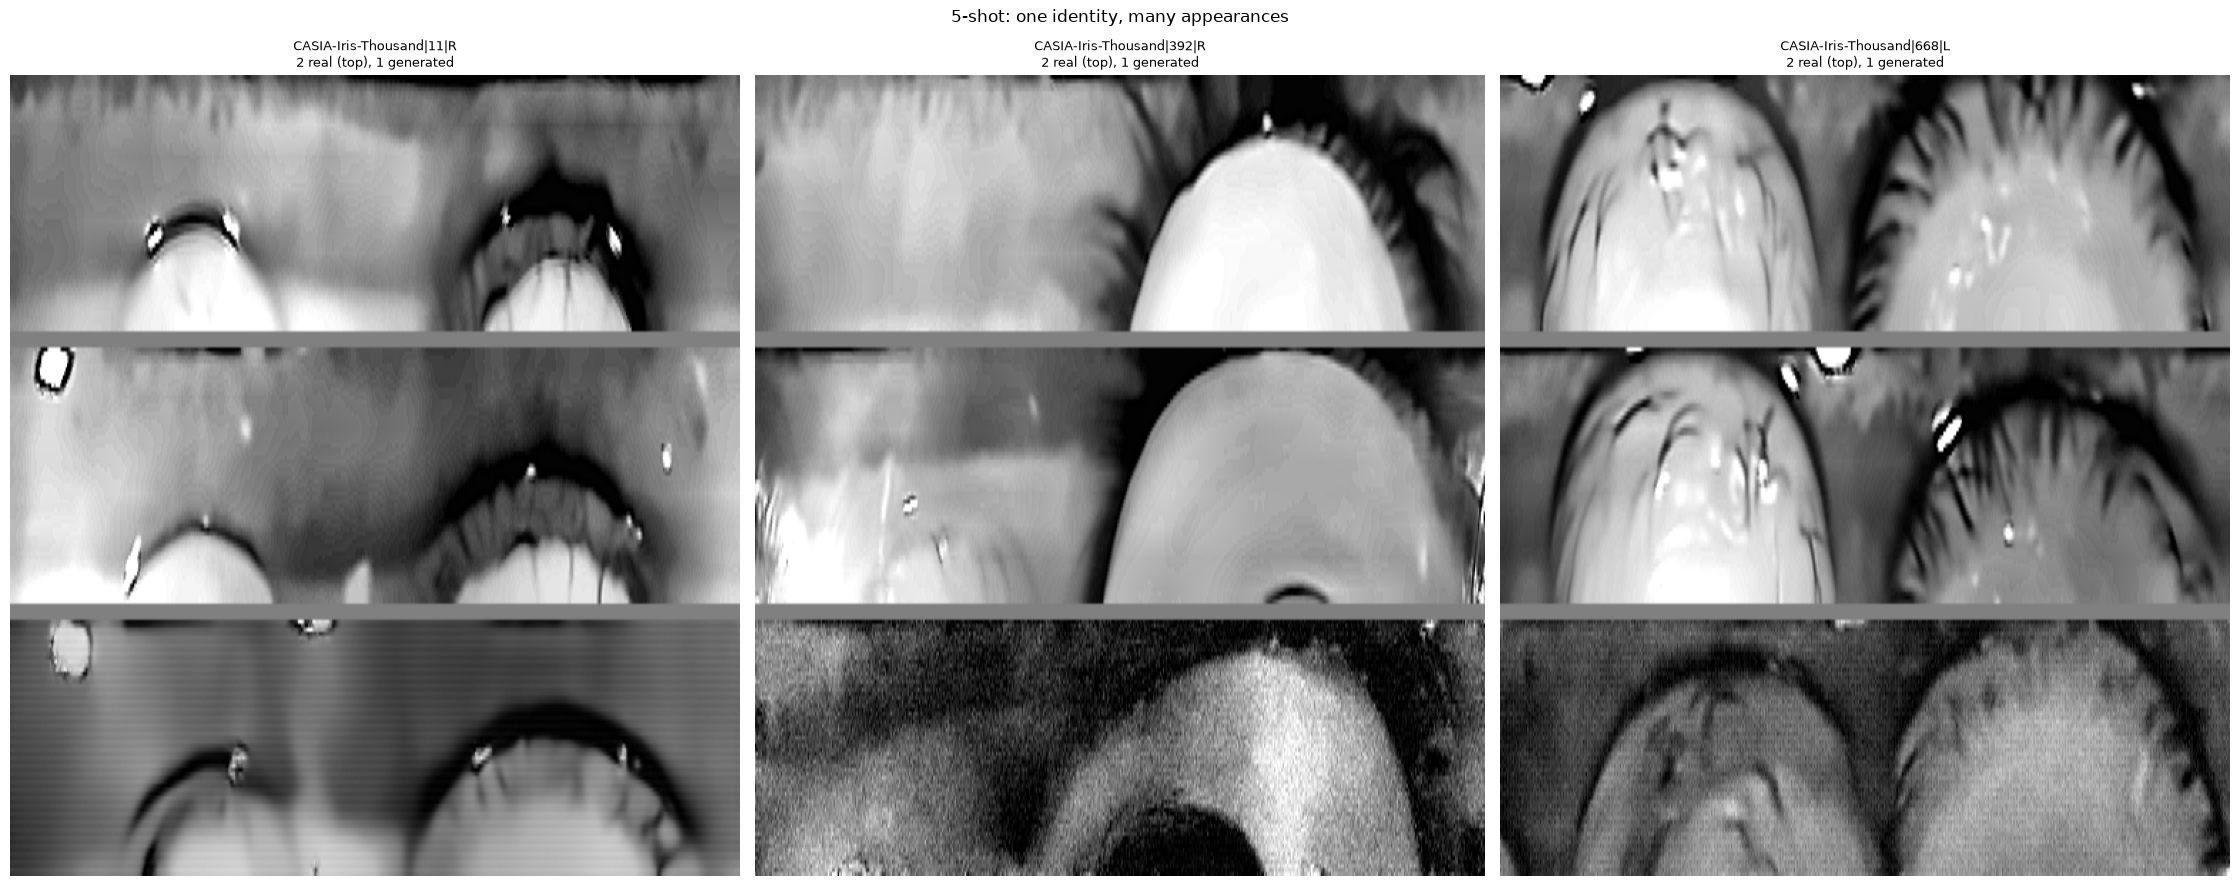

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_identity_to_variation_5shot.png


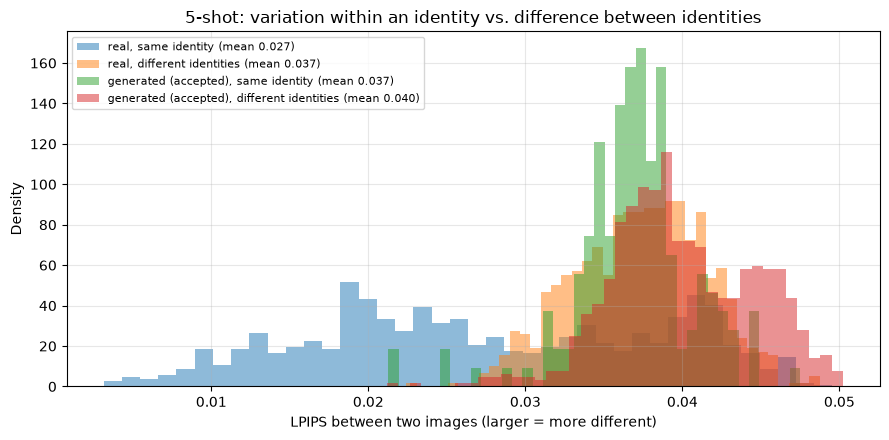

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_distance_distributions_5shot.png


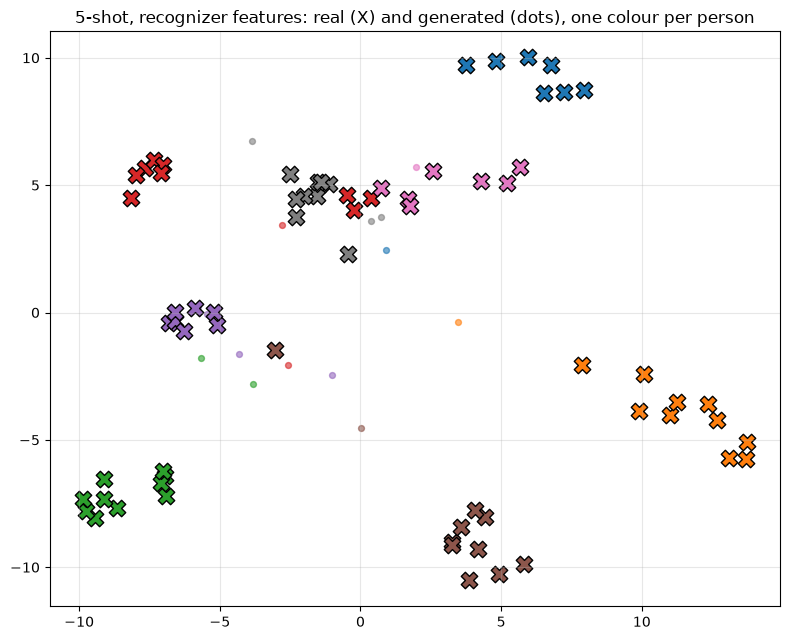

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_feature_projection_5shot.png


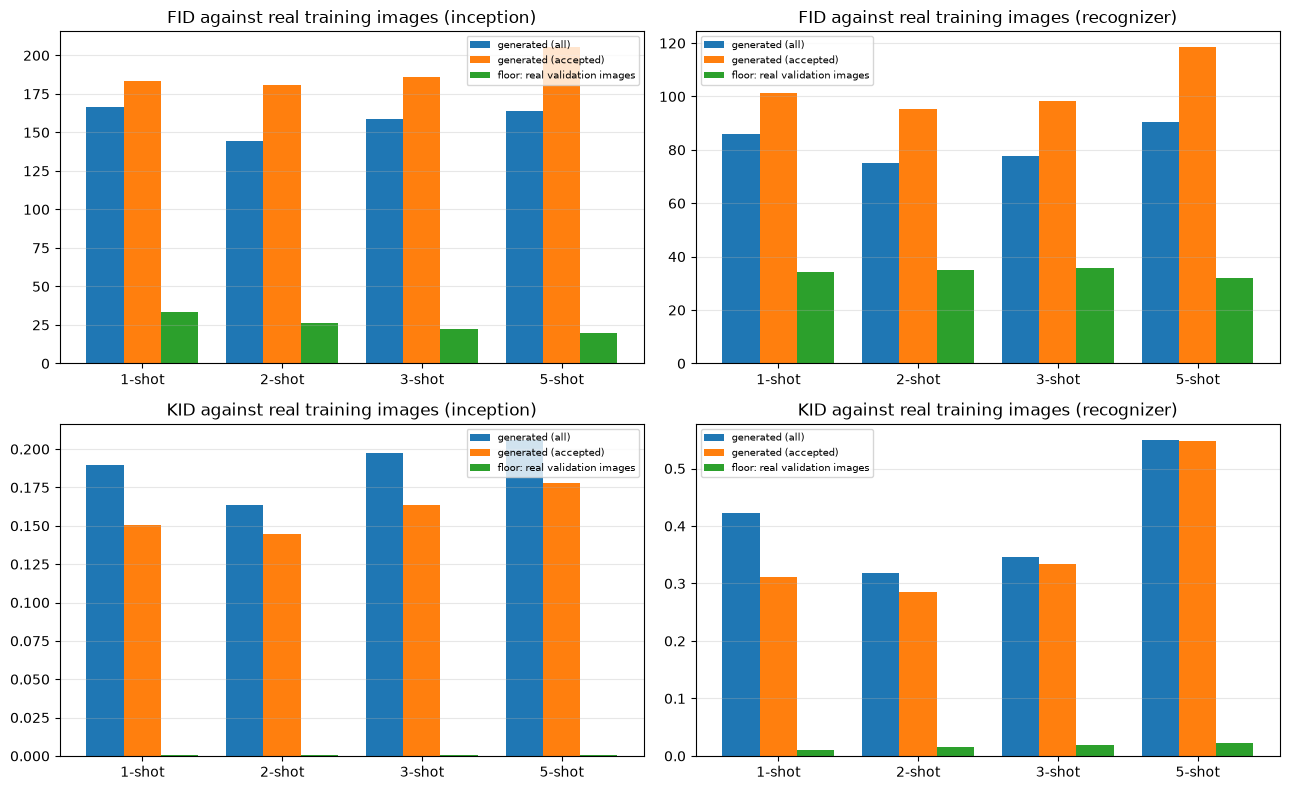

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity\diversity_fid_kid.png


In [15]:
# ============================================================
# 14. Figures
# ============================================================

largest_shot = int(pairs_table["shot"].max())
largest_run = make_run_id(largest_shot)
figure_source = accepted_manifest if accepted_manifest is not None else synthetic_manifest
figure_source = figure_source[(figure_source["shot"] == largest_shot) & (figure_source["generator_run_id"] == largest_run)]
if len(figure_source) == 0:      # nothing was accepted: show the generated images instead
    figure_source = synthetic_manifest[(synthetic_manifest["shot"] == largest_shot)
                                       & (synthetic_manifest["generator_run_id"] == largest_run)]

def composite(strips, gap=4):
    parts = []
    for i, strip in enumerate(strips):
        parts.append(strip)
        if i < len(strips) - 1:
            parts.append(np.full((gap, strip.shape[1]), 0.5, dtype=strip.dtype))
    return np.vstack(parts)


# ---- 1. real and generated side by side ----
real_all = long_manifest[(long_manifest["shot"] == largest_shot) & (long_manifest["split"] == "train")
                         & (long_manifest["role"] == "support") & (long_manifest["dataset"].isin(TRAIN_DATASETS))]
classes_with_images = sorted(figure_source["class_id"].unique())
shown = classes_with_images[::max(1, len(classes_with_images) // FIGURE_IDENTITIES)][:FIGURE_IDENTITIES]

if shown:
    fig, axes = plt.subplots(1, len(shown), figsize=(7.5 * len(shown), 9), squeeze=False)
    for ax, class_id in zip(axes[0], shown):
        real = load_image_tensor(real_all[real_all["class_id"] == class_id].head(2)).numpy().astype(np.float32) / 255.0
        rows = figure_source[figure_source["class_id"] == class_id].sort_values("synth_index")
        pick = rows.iloc[np.unique(np.linspace(0, len(rows) - 1, FIGURE_GENERATED).round().astype(int))]
        generated_strips = [read_synthetic(SYNTHETIC_DIR / p).astype(np.float32) / 255.0 for p in pick["relative_path"]]
        ax.imshow(composite(list(real) + generated_strips), cmap="gray", vmin=0, vmax=1, aspect="auto")
        ax.set_title(f"{class_id}\n{len(real)} real (top), {len(generated_strips)} generated", fontsize=9)
        ax.axis("off")
    plt.suptitle(f"{largest_shot}-shot: one identity, many appearances", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"diversity_identity_to_variation_{largest_shot}shot.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

# ---- 2. distance distributions ----
distance_data = np.load(DISTANCES_DIR / f"{largest_run}.npz")
shown_set = "accepted" if f"accepted_within__{primary_metric}" in distance_data.files else "all"
metric_label = {"lpips": "LPIPS", "msssim": "1 - MS-SSIM", "l1": "pixel L1"}[primary_metric]

fig, ax = plt.subplots(figsize=(9, 4.5))
for kind, label in [("real_within", "real, same identity"), ("real_between", "real, different identities"),
                    (f"{shown_set}_within", f"generated ({shown_set}), same identity"),
                    (f"{shown_set}_between", f"generated ({shown_set}), different identities")]:
    values = distance_data[f"{kind}__{primary_metric}"]
    values = values[np.isfinite(values)]
    if len(values):
        ax.hist(values, bins=40, alpha=0.5, density=True, label=f"{label} (mean {values.mean():.3f})")

ax.set_xlabel(f"{metric_label} between two images (larger = more different)")
ax.set_ylabel("Density")
ax.set_title(f"{largest_shot}-shot: variation within an identity vs. difference between identities")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
path = RESULTS_DIR / f"diversity_distance_distributions_{largest_shot}shot.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


# ---- 3. 2-D projection of the features ----
def show_feature_projection(shot):
    extractors = get_extractors(shot)
    if not extractors:
        print("No feature extractor available; skipping the projection.")
        return

    space = "recognizer" if "recognizer" in extractors else next(iter(extractors))
    source = figure_source[figure_source["shot"] == shot]
    classes = sorted(source["class_id"].unique())
    classes = classes[::max(1, len(classes) // PCA_IDENTITIES)][:PCA_IDENTITIES]

    real_rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["split"] == "train")
                              & (long_manifest["dataset"].isin(TRAIN_DATASETS)) & (long_manifest["class_id"].isin(classes))]
    generated_rows = source[source["class_id"].isin(classes)]

    real_features = extract_features(extractors[space], load_image_tensor(real_rows))
    generated_features = extract_features(extractors[space], stack_synthetic(generated_rows["relative_path"]))

    both = torch.cat([real_features, generated_features])
    centered = both - both.mean(dim=0, keepdim=True)
    _, _, components = torch.linalg.svd(centered, full_matrices=False)
    points = torch.matmul(centered, components[:2].t()).numpy()
    real_points, generated_points = points[:len(real_features)], points[len(real_features):]

    fig, ax = plt.subplots(figsize=(8, 6.5))
    for color_index, class_id in enumerate(classes):
        color = plt.cm.tab10(color_index % 10)
        real_mask = (real_rows["class_id"] == class_id).to_numpy()
        generated_mask = (generated_rows["class_id"] == class_id).to_numpy()
        ax.scatter(generated_points[generated_mask, 0], generated_points[generated_mask, 1], s=18, color=color, alpha=0.6)
        ax.scatter(real_points[real_mask, 0], real_points[real_mask, 1], s=140, color=color, marker="X", edgecolor="black")

    ax.set_title(f"{shot}-shot, {space} features: real (X) and generated (dots), one colour per person")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    path = RESULTS_DIR / f"diversity_feature_projection_{shot}shot.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


show_feature_projection(largest_shot)

# ---- 4. FID and KID per shot ----
if len(fid_table):
    reference_rows = fid_table[fid_table["reference"] == "real_train"]
    spaces = sorted(reference_rows["space"].unique())
    fig, axes = plt.subplots(2, len(spaces), figsize=(6.5 * len(spaces), 8), squeeze=False)

    for column, space in enumerate(spaces):
        for row, (metric, title) in enumerate([("fid", "FID"), ("kid_mean", "KID")]):
            ax = axes[row, column]
            subset = reference_rows[reference_rows["space"] == space]
            candidates = [c for c in ["gen_all", "gen_accepted", "real_val"] if c in set(subset["candidate"])]
            shots = sorted(subset["shot"].unique())
            width = 0.8 / max(len(candidates), 1)

            for k, candidate in enumerate(candidates):
                values = [float(subset[(subset["shot"] == s) & (subset["candidate"] == candidate)][metric].iloc[0])
                          if len(subset[(subset["shot"] == s) & (subset["candidate"] == candidate)]) else np.nan for s in shots]
                label = {"gen_all": "generated (all)", "gen_accepted": "generated (accepted)", "real_val": "floor: real validation images"}[candidate]
                ax.bar(np.arange(len(shots)) + k * width, values, width, label=label)

            ax.set_xticks(np.arange(len(shots)) + width * (len(candidates) - 1) / 2)
            ax.set_xticklabels([f"{s}-shot" for s in shots])
            ax.set_title(f"{title} against real training images ({space})")
            ax.grid(axis="y", alpha=0.3)
            ax.legend(fontsize=7)

    plt.tight_layout()
    path = RESULTS_DIR / "diversity_fid_kid.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

## 15. Sanity checks

**Stop the notebook if:**
- a planned run is missing, or a leakage guard failed;
- the distances of the pairwise analysis (L1 and MS-SSIM) are not finite, or there are no pairs;
- no FID/KID value could be computed in any feature space;
- the accepted images are not a subset of the generated images.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the diversity ratio is below 0.5 (images of one identity are much more alike than real ones: mode collapse) or above 2 (more varied than real: noise or artefacts?);
- the separation is not above 1 (images of one person are not closer than images of different people);
- the novelty ratio is below 0.2 (generated images are almost copies of the real ones);
- the accepted images have less than 80% of the variation of all generated images (the identity filter removed variation);
- FID is more than 5 times the real-vs-real floor (the generated images are far from real ones relative to a new real set).

In [16]:
# ============================================================
# 15. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(shot) for shot in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the leakage guards", bool(runs_table["leakage_checks_passed"].all()))

add_check("every pairwise analysis has within-identity pairs", bool((pairs_table["pairs_within"] > 0).all()))
add_check("L1 and MS-SSIM distances are finite",
          bool(np.isfinite(pairs_table[["within_l1", "within_msssim", "between_l1", "between_msssim"]].to_numpy()).all()))
add_check("FID and KID were computed in at least one feature space",
          len(fid_table) > 0 and bool(np.isfinite(fid_table["fid"]).any()) and bool(np.isfinite(fid_table["kid_mean"]).any()))

if accepted_manifest is not None:
    add_check("the accepted images are a subset of the generated images",
              set(accepted_manifest["verify_id"]) <= set(synthetic_manifest["verify_id"]))

for _, row in pairs_table.iterrows():
    label = f"{int(row['shot'])}-shot / {row['generated_set']}"
    diversity, separation, novelty = (row[f"diversity_ratio_{primary_metric}"], row[f"separation_{primary_metric}"],
                                      row[f"novelty_ratio_{primary_metric}"])

    if np.isfinite(diversity):
        add_check(f"{label}: diversity ratio is between 0.5 and 2", 0.5 <= diversity <= 2.0, f"{diversity:.2f} ({primary_metric})", critical=False)
    if np.isfinite(separation):
        add_check(f"{label}: images of one identity are closer to each other than to other identities", separation > 1.0,
                  f"separation {separation:.2f}, real {row[f'real_separation_{primary_metric}']:.2f}", critical=False)
    if np.isfinite(novelty):
        add_check(f"{label}: generated images are not copies of the real images", novelty >= 0.2, f"novelty ratio {novelty:.2f}", critical=False)

if {"all", "accepted"} <= set(pairs_table["generated_set"]):
    for shot, group in pairs_table.groupby("shot"):
        by_set = group.set_index("generated_set")[f"within_{primary_metric}"]
        kept = ratio(by_set.get("accepted", np.nan), by_set.get("all", np.nan))
        if np.isfinite(kept):
            add_check(f"{int(shot)}-shot: the identity filter kept at least 80% of the variation", kept >= 0.8,
                      f"accepted / all = {kept:.2f}", critical=False)

for _, row in diversity_report.iterrows():
    for space in spaces_in_report:
        floor, value = row.get(f"fid_floor_{space}", np.nan), row.get(f"fid_{space}", np.nan)
        if np.isfinite(floor) and floor > 0 and np.isfinite(value):
            add_check(f"{int(row['shot'])}-shot / {row['generated_set']} / {space}: FID is within 5 times the real-vs-real floor",
                      value <= 5 * floor, f"FID {value:.2f}, floor {floor:.2f}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "diversity_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "diversity_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical diversity checks failed: {failed_names}"
print("\nDiversity sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the leakage guards
[PASS] every pairwise analysis has within-identity pairs
[PASS] L1 and MS-SSIM distances are finite
[PASS] FID and KID were computed in at least one feature space
[PASS] the accepted images are a subset of the generated images
[PASS] 1-shot / all: diversity ratio is between 0.5 and 2  (1.44 (lpips))
[PASS] 1-shot / all: images of one identity are closer to each other than to other identities  (separation 1.08, real 1.46)
[PASS] 1-shot / all: generated images are not copies of the real images  (novelty ratio 1.55)
[PASS] 1-shot / accepted: diversity ratio is between 0.5 and 2  (1.36 (lpips))
[PASS] 1-shot / accepted: images of one identity are closer to each other than to other identities  (separation 1.14, real 1.46)
[PASS] 1-shot / accepted: generated images are not copies of the real images  (novelty ratio 1.51)
[PASS] 2-shot / all: diversity ratio is between 0.5 and 2  (1.50 (lpips))
[PASS] 2

## 16. Final outputs

At the end of Notebook 12, the project should contain:

```text
results/synthetic_diversity/
├── diversity_report.csv           the report: FID, KID, LPIPS, MS-SSIM and ratios, per shot and generated set
├── diversity_pairs.csv            identity-to-variation table
├── diversity_fid_kid.csv          FID and KID of every comparison
├── diversity_runs.csv, diversity_sanity_checks.csv
├── distances/<run_id>.npz         the raw pair distances behind the figures
├── runs/                          one JSON record per shot
└── diversity_identity_to_variation_<K>shot.png, diversity_distance_distributions_<K>shot.png,
    diversity_feature_projection_<K>shot.png, diversity_fid_kid.png
```

In [17]:
# ============================================================
# 16. Final output listing
# ============================================================

print("Notebook 12 results:", RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nDistance files: {len(list(DISTANCES_DIR.glob('*.npz')))} | run records: {len(list(RUNS_DIR.glob('*.json')))}")
print(f"LPIPS implementation: {PERCEPTUAL.implementation}")
print("\nNotebook 12 completed.")

Notebook 12 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_diversity
- diversity_distance_distributions_5shot.png
- diversity_feature_projection_5shot.png
- diversity_fid_kid.csv
- diversity_fid_kid.png
- diversity_identity_to_variation_5shot.png
- diversity_pairs.csv
- diversity_report.csv
- diversity_runs.csv
- diversity_sanity_checks.csv

Distance files: 4 | run records: 4
LPIPS implementation: unweighted AlexNet features (LPIPS proxy, no learned weights)

Notebook 12 completed.


## 17. What this notebook hands to the rest of the project

```text
Notebooks 10 and 11            Notebook 12                         Notebooks 13, 16, 17
Generated and accepted  --->   Diversity measurements        --->   13: choose how many synthetic images to use
synthetic images               (diversity_report.csv)               16: ablations   17: publication tables
```

### How `diversity_report.csv` is used

| Notebook | Use |
|---|---|
| **13 Final recognition** | If the diversity ratio of the accepted images is far below 1, adding more of them gives little new information; consider fewer images per identity or a generator with more variation |
| **16 Ablations** | Relate the recognition gain to the diversity measures: different guidance scales, numbers of synthetic images per identity, and filter thresholds |
| **17 Performance comparison** | The FID / KID / LPIPS columns of the paper's results table (`fid_<space>`, `kid_<space>`, `within_lpips`, ...). Report the **feature space and the LPIPS implementation** with every number |
| **15 Explainability** | The feature projection and the identity-to-variation figure show the generated images next to the real ones |

### Rules

1. The numbers describe the **synthetic training images**. Never compute them on validation or test images except as the stated real reference and floor.
2. FID depends on the sample size; compare FID values only between sets of similar size, or use KID.
3. State that the Inception-space FID uses torchvision weights and enlarged grayscale strips, so it is **not comparable with published FID values**.
4. Report `CONFIG_HASH`, the generator seed, and `DIVERSITY_IDENTITIES` / `PAIRS_PER_IDENTITY` with every number.

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Diversity ratio far below 1 | Mode collapse: the appearance code is ignored or guidance is too strong | Lower `GUIDANCE_SCALE` (Notebook 9/10), raise `AUGMENT_PROB` (Notebook 9) |
| Diversity ratio far above 1 | Noisy or artefact-laden images | Look at the figures; train the generator longer |
| Separation at or below 1 | Identity is not preserved: images of one person are as different as images of different people | Raise the guidance scale; improve the generator; check Notebook 11's acceptance rate |
| Novelty ratio near 0 | The generator copies its real training images | Raise `AUGMENT_PROB`, lower the guidance scale, train less |
| Accepted images much less varied than all generated | The identity filter keeps only images close to the real ones | Relax `TARGET_FAR` (Notebook 11) |
| FID much larger than the floor but diversity looks fine | The images are varied but not realistic | Train the generator longer; check the figures |
| Large difference between `inception` and `recognizer` FID | ImageNet features are less relevant for iris textures | Trust the `recognizer` space for iris-specific realism, and report both |